In [177]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error,r2_score

In [155]:
df = pd.read_csv("uber.csv")

In [156]:
df.head()

,Unnamed: 0,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,24238194,2015-05-07 19:52:06.0000003,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1
1,27835199,2009-07-17 20:04:56.0000002,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1
2,44984355,2009-08-24 21:45:00.00000061,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1
3,25894730,2009-06-26 08:22:21.0000001,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3
4,17610152,2014-08-28 17:47:00.000000188,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5


In [157]:
df.dtypes

Unnamed: 0             int64
key                   object
fare_amount          float64
pickup_datetime       object
pickup_longitude     float64
pickup_latitude      float64
dropoff_longitude    float64
dropoff_latitude     float64
passenger_count        int64
dtype: object

In [158]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 9 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Unnamed: 0         200000 non-null  int64  
 1   key                200000 non-null  object 
 2   fare_amount        200000 non-null  float64
 3   pickup_datetime    200000 non-null  object 
 4   pickup_longitude   200000 non-null  float64
 5   pickup_latitude    200000 non-null  float64
 6   dropoff_longitude  199999 non-null  float64
 7   dropoff_latitude   199999 non-null  float64
 8   passenger_count    200000 non-null  int64  
dtypes: float64(5), int64(2), object(2)
memory usage: 13.7+ MB
None


In [159]:
df.isnull().sum()

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    1
dropoff_latitude     1
passenger_count      0
dtype: int64

In [160]:
df.dropna(inplace=True)

In [161]:
import math;

def Euclidean_distance(lat1,lon1,lat2,lon2):
    dlat = lat2 - lat1;
    dlon = lon2 - lon1;
    dist = math.sqrt(dlat**2 + dlon**2);
    return dist

df['distance'] = df.apply(
    lambda row: Euclidean_distance(
        row['pickup_latitude'],
        row['pickup_longitude'],
        row['dropoff_latitude'],
        row['dropoff_longitude']
    ),axis=1
)

In [162]:
df.drop(['Unnamed: 0','key'],axis=1,inplace=True)

In [163]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance
0,7.5,2015-05-07 19:52:06 UTC,-73.999817,40.738354,-73.999512,40.723217,1,0.015140
1,7.7,2009-07-17 20:04:56 UTC,-73.994355,40.728225,-73.994710,40.750325,1,0.022103
2,12.9,2009-08-24 21:45:00 UTC,-74.005043,40.740770,-73.962565,40.772647,1,0.053109
3,5.3,2009-06-26 08:22:21 UTC,-73.976124,40.790844,-73.965316,40.803349,3,0.016528
4,16.0,2014-08-28 17:47:00 UTC,-73.925023,40.744085,-73.973082,40.761247,5,0.051031


In [164]:
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] < 100)]
df = df[(df['passenger_count'] > 0) & (df['passenger_count'] <= 6)]
df = df[df['distance'] < 5]

In [165]:
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])
df['hour'] = df['pickup_datetime'].dt.hour
df['day_of_week'] = df["pickup_datetime"].dt.dayofweek

In [166]:
df.head()

,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count,distance,hour,day_of_week
0,7.5,2015-05-07 19:52:06+00:00,-73.999817,40.738354,-73.999512,40.723217,1,0.015140,19,3
1,7.7,2009-07-17 20:04:56+00:00,-73.994355,40.728225,-73.994710,40.750325,1,0.022103,20,4
2,12.9,2009-08-24 21:45:00+00:00,-74.005043,40.740770,-73.962565,40.772647,1,0.053109,21,0
3,5.3,2009-06-26 08:22:21+00:00,-73.976124,40.790844,-73.965316,40.803349,3,0.016528,8,4
4,16.0,2014-08-28 17:47:00+00:00,-73.925023,40.744085,-73.973082,40.761247,5,0.051031,17,3


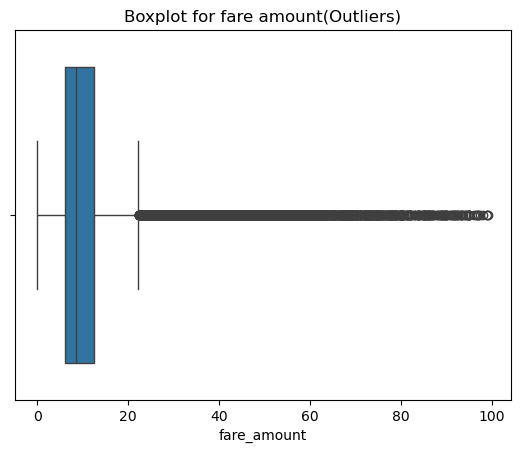

In [167]:
## Boxplot for fare amount
sns.boxplot(x = df['fare_amount'])
plt.title("Boxplot for fare amount(Outliers)")
plt.show()

In [168]:
Q1 = df['fare_amount'].quantile(0.25)
Q3 = df['fare_amount'].quantile(0.75)

IQR = Q3 - Q1
lower = Q1 - 1.5*IQR;
upper = Q3 + 1.5*IQR;
print("Q1:",Q1);
print("Q3:",Q3);
print("IQR:",IQR);
print("Lower:",lower,"Upper:",upper);

Q1: 6.0
Q3: 12.5
IQR: 6.5
Lower: -3.75 Upper: 22.25


In [169]:
outliers = df[(df['fare_amount'] < lower) | (df['fare_amount'] > upper)]
print(len(outliers))

16957


In [170]:
df = df[(df['fare_amount'] > 0) & (df['fare_amount'] <= upper)]
print(df.shape)

(181789, 10)


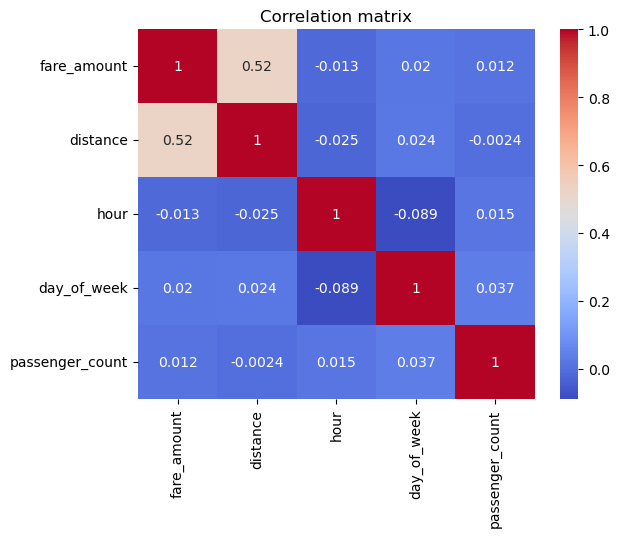

In [171]:
corr = df[['fare_amount','distance','hour','day_of_week','passenger_count']].corr()
sns.heatmap(corr,annot=True,cmap='coolwarm')
plt.title('Correlation matrix')
plt.show()

In [173]:
X = df[['distance','passenger_count','hour','day_of_week']]
y = df['fare_amount']

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)


In [175]:
#Linear Regression

lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred_lr = lr.predict(X_test)

In [176]:
#Random Forest Regression

rf = RandomForestRegressor(n_estimators=100,random_state=42)
rf.fit(X_train,y_train);
y_pred_rf = rf.predict(X_test)

In [178]:
def evaluate(y_test,y_pred,model_name):
    rmse = np.sqrt(mean_squared_error(y_test,y_pred))
    r2 = r2_score(y_test,y_pred)
    print(f"{model_name} Results:")
    print(f"R2 Score: {r2:.4f}")
    print(f"Root Mean Squared Error: {rmse:.4f}")

In [179]:
evaluate(y_test,y_pred_lr,"Linear Regression")
evaluate(y_test,y_pred_rf,"Random Forest Regression")

Linear Regression Results:
R2 Score: 0.2654
Root Mean Squared Error: 3.5556
Random Forest Regression Results:
R2 Score: 0.6377
Root Mean Squared Error: 2.4968
